# Fehleranalyse – Betrugserkennung bei Strom und Gas
**Team 5 (Roland, Leo, Tobias)** · Meilenstein 3

Wo liegt unser bestes Modell daneben, und welche Features sind ihm wichtig?

Daten: `data/fd_features.csv` · Split: `data/fd_split.csv` · Modell: `models/fd_best_model.joblib` (aus `07_modelle.ipynb`)

| # | Schritt |
|---|---|
| 1 | Setup und Daten laden |
| 2 | Vorhersagen per Cross-Validation |
| 3 | Welche Schwelle? |
| 4 | Konfusionsmatrix |
| 5 | Welche Betrüger übersieht das Modell? |
| 6 | Wo liegt das Modell daneben? |
| 7 | Welche Features sind wichtig? |
| 8 | Wie gut ist das Modell ohne `n_counters`? |
| 9 | Fazit |

## 1 · Setup und Daten laden

In [13]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import cross_val_predict

from fd_utils import cv, evaluate, evaluate_cv

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

DATA_DIR = Path("data")
MODEL_DIR = Path("models")

In [14]:
df = pd.read_csv(DATA_DIR / "fd_features.csv")
df_split = pd.read_csv(DATA_DIR / "fd_split.csv")
df = df.merge(df_split, on="client_id", how="left")

df_train = df[df["split"] == "train"].reset_index(drop=True)

nicht_features = ["client_id", "creation_date", "split", "target"]
X_train = df_train.drop(columns=nicht_features)
y_train = df_train["target"]

model = joblib.load(MODEL_DIR / "fd_best_model.joblib")
print("X_train:", X_train.shape)
model

X_train: (108394, 30)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractio

## 2 · Vorhersagen per Cross-Validation
Wir dürfen das Modell nicht auf denselben Kunden bewerten, auf denen es trainiert wurde. Mit `cross_val_predict` bekommt jeder Kunde eine Vorhersage von einem Modell, das ihn **nicht** gesehen hat (dieselben 5 Folds wie in `fd_utils.py`). Den Test-Teil heben wir weiter für `09_final.ipynb` auf.

In [ ]:
proba = cross_val_predict(clone(model), X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

df_train["proba"] = proba
evaluate(y_train, proba)

## 3 · Welche Schwelle?
Normalerweise sagt ein Modell ab einer Wahrscheinlichkeit von 0,5 "Betrug". Für STEG ist aber eine andere Frage wichtiger: **Die Kontrolleure können nicht alle Kunden besuchen.** Nehmen wir an, sie schaffen **10 % der Kunden**. Dann ist die Schwelle der Wert, ab dem ein Kunde zu den verdächtigsten 10 % gehört.

In [ ]:
schwelle = df_train["proba"].quantile(0.9)
print(f"Schwelle für die Top 10 %: {schwelle:.3f}")

print("Mit Schwelle 0,5:     ", evaluate(y_train, proba, threshold=0.5))
print("Mit Schwelle Top 10 %:", evaluate(y_train, proba, threshold=schwelle))

Schwelle für die Top 10 %: 0.634
Mit Schwelle 0,5:      {'ROC-AUC': 0.847, 'Recall': 0.664, 'Precision': 0.202}
Mit Schwelle Top 10 %: {'ROC-AUC': 0.847, 'Recall': 0.492, 'Precision': 0.275}


**Was fällt auf?**
* Bei Schwelle 0,5 findet das Modell 66 % der Betrüger, aber nur 20 % der Verdachtsfälle sind wirklich Betrug.
* Mit der **Top-10-%-Schwelle** (0,63) findet es **knapp die Hälfte aller Betrüger (49 %)**, und **28 %** der Verdachtsfälle sind Betrug. Das ist fünfmal so viel wie bei zufälligen Kontrollen (5,6 %).

**Entscheidung:** Ab hier benutzen wir die Top-10-%-Schwelle.

## 4 · Konfusionsmatrix (Schwelle Top 10 %)

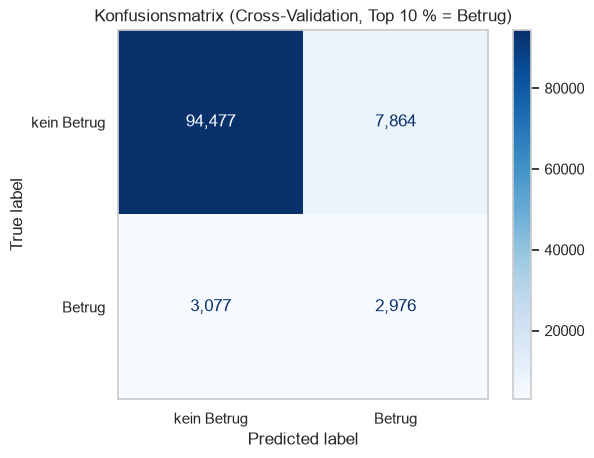

array([[94477,  7864],
       [ 3077,  2976]])

In [ ]:
df_train["vorhersage"] = (df_train["proba"] >= schwelle).astype(int)

ConfusionMatrixDisplay.from_predictions(y_train, df_train["vorhersage"],
                                        display_labels=["kein Betrug", "Betrug"], cmap="Blues", values_format=",")
plt.title("Konfusionsmatrix (Cross-Validation, Top 10 % = Betrug)")
plt.grid(False)
plt.show()

confusion_matrix(y_train, df_train["vorhersage"])

**Was fällt auf?**
* 2.976 Betrüger richtig erkannt, 3.077 übersehen.
* 7.864 falsche Alarme. Das sind viele, aber ein Teil davon könnten Betrüger sein, die nur noch nie erwischt wurden (`target = 0` heißt "nicht erwischt", siehe EDA).

## 5 · Welche Betrüger übersieht das Modell?
Wir teilen die Kunden in vier Gruppen auf:

| Gruppe | Bedeutung |
|---|---|
| richtig erkannt (TP) | Betrüger, Modell sagt Betrug |
| übersehen (FN) | Betrüger, Modell sagt kein Betrug |
| falscher Alarm (FP) | kein Betrug, Modell sagt Betrug |
| richtig in Ruhe gelassen (TN) | kein Betrug, Modell sagt kein Betrug |

In [ ]:
df_train["gruppe"] = "TN: richtig in Ruhe gelassen"
df_train.loc[(df_train["target"] == 1) & (df_train["vorhersage"] == 1), "gruppe"] = "TP: richtig erkannt"
df_train.loc[(df_train["target"] == 1) & (df_train["vorhersage"] == 0), "gruppe"] = "FN: übersehen"
df_train.loc[(df_train["target"] == 0) & (df_train["vorhersage"] == 1), "gruppe"] = "FP: falscher Alarm"

vergleich = ["n_invoices", "n_counters", "contract_age_years", "share_gas", "share_zero",
             "cons_median_elec", "month_std_elec", "max_drop", "proba"]

df_train.groupby("gruppe")[vergleich].median().T.round(2)

gruppe,FN: übersehen,FP: falscher Alarm,TN: richtig in Ruhe gelassen,TP: richtig erkannt
n_invoices,37.00,48.00,27.00,46.00
n_counters,2.00,3.00,1.00,3.00
contract_age_years,13.94,19.13,13.44,20.95
share_gas,0.37,0.37,0.00,0.37
share_zero,0.04,0.05,0.01,0.04
cons_median_elec,478.00,542.50,413.00,481.25
month_std_elec,79.04,131.83,52.18,108.86
max_drop,205.33,376.00,119.75,308.00
proba,0.41,0.72,0.17,0.78


**Was fällt auf?**
* **Übersehene Betrüger (FN)** sehen aus wie normale Kunden: weniger Zähler (2 statt 3), weniger Rechnungen (37 statt 46), kürzer Kunde (14 statt 21 Jahre) und kleinere Sprünge im Verbrauch.
* **Falsche Alarme (FP)** sehen dagegen aus wie die erkannten Betrüger: 3 Zähler, viele Rechnungen, unruhiger Verbrauch. Das Modell kann die beiden Gruppen mit unseren Daten kaum unterscheiden.

## 6 · Wo liegt das Modell daneben?
Wie viele der Betrüger findet das Modell in verschiedenen Kundengruppen (= Recall pro Gruppe)?

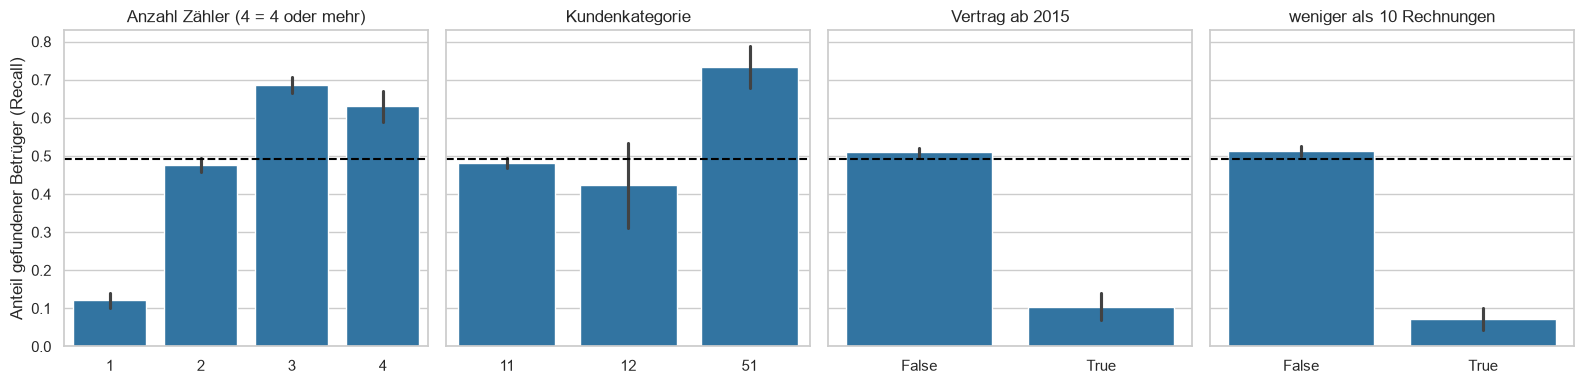

In [ ]:
betrueger = df_train[df_train["target"] == 1].copy()

betrueger["n_counters_gruppe"] = betrueger["n_counters"].clip(upper=4)
betrueger["vertrag_ab_2015"] = pd.to_datetime(betrueger["creation_date"]).dt.year >= 2015
betrueger["wenige_rechnungen"] = betrueger["n_invoices"] < 10

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, spalte, titel in zip(
    axes,
    ["n_counters_gruppe", "client_catg", "vertrag_ab_2015", "wenige_rechnungen"],
    ["Anzahl Zähler (4 = 4 oder mehr)", "Kundenkategorie", "Vertrag ab 2015", "weniger als 10 Rechnungen"],
):
    sns.barplot(data=betrueger, x=spalte, y="vorhersage", color="tab:blue", ax=ax)
    ax.axhline(betrueger["vorhersage"].mean(), color="black", linestyle="--")
    ax.set_title(titel)
    ax.set_xlabel("")
axes[0].set_ylabel("Anteil gefundener Betrüger (Recall)")
plt.tight_layout()
plt.show()

In [ ]:
for spalte in ["n_counters_gruppe", "client_catg", "vertrag_ab_2015", "wenige_rechnungen"]:
    tabelle = betrueger.groupby(spalte)["vorhersage"].agg(["count", "mean"])
    tabelle.columns = ["Betrüger", "Recall"]
    display(tabelle.round(3))

,Betrüger,Recall
n_counters_gruppe,,
1,1039,0.121
2,2667,0.475
3,1813,0.687
4,534,0.631


,Betrüger,Recall
client_catg,,
11,5749,0.483
12,71,0.423
51,233,0.734


,Betrüger,Recall
vertrag_ab_2015,,
False,5781,0.510
True,272,0.103


,Betrüger,Recall
wenige_rechnungen,,
False,5758,0.513
True,295,0.071


**Was fällt auf?**
* **Kunden mit nur einem Zähler:** Nur 12 % der Betrüger werden gefunden. Das Modell verlässt sich stark auf die Anzahl der Zähler.
* **Neue Kunden (ab 2015)** und **Kunden mit wenigen Rechnungen:** nur 10 % bzw. 7 %. Dort gibt es wenig Historie, aus der das Modell etwas ablesen kann.
* **Kategorie 51:** 73 % gefunden. Diese Gruppe hat ohnehin viel Betrug (EDA 6.2).

## 7 · Welche Features sind wichtig?
Ein Random Forest merkt sich beim Training, wie sehr jede Spalte geholfen hat, Betrug und kein Betrug zu trennen (`feature_importances_`, wie in week07). Alle Werte zusammen ergeben 1.

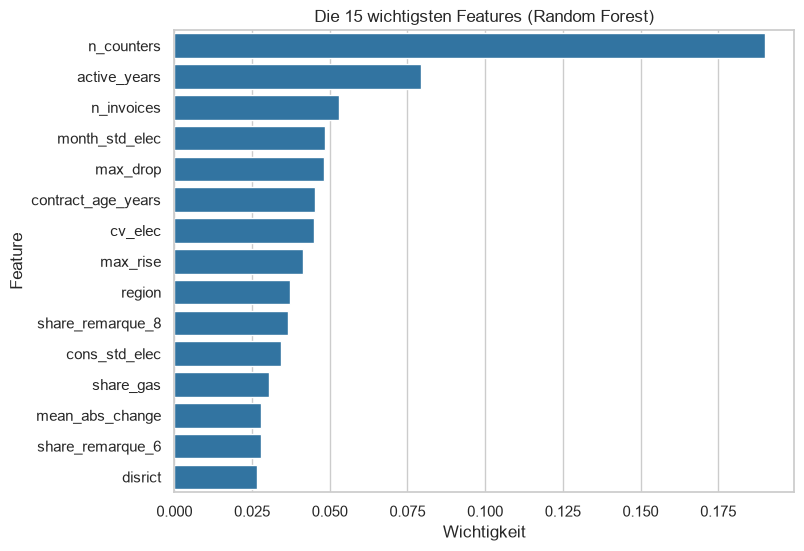

,Feature,Wichtigkeit
4,n_counters,0.1900
16,active_years,0.0795
3,n_invoices,0.0529
18,month_std_elec,0.0484
24,max_drop,0.0483
15,contract_age_years,0.0453
28,cv_elec,0.0448
25,max_rise,0.0412
2,region,0.0372
22,share_remarque_8,0.0366


In [ ]:
df_wichtig = pd.DataFrame({
    "Feature": X_train.columns,
    "Wichtigkeit": model.feature_importances_,
}).sort_values("Wichtigkeit", ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(data=df_wichtig.head(15), x="Wichtigkeit", y="Feature", color="tab:blue")
plt.title("Die 15 wichtigsten Features (Random Forest)")
plt.show()

df_wichtig.head(15).round(4)

**Was fällt auf?**
* **`n_counters` ist mit Abstand am wichtigsten** (0,19).
* Danach kommen `active_years` und `n_invoices`, also wie lange und wie viel ein Kunde schon abgerechnet wird.
* Die neuen Features aus `06_features.ipynb` sind weit oben dabei: `month_std_elec`, `max_drop`, `cv_elec` und `max_rise` liegen alle unter den Top 8. Der unruhige Verbrauch hilft dem Modell also wirklich.

## 8 · Wie gut ist das Modell ohne `n_counters`?
`n_counters` ist das wichtigste Feature. Aber: Wird ein Zähler oft erst **nach** dem Erwischen ausgetauscht, dann ist ein zusätzlicher Zähler eine **Folge** des Betrugs und kein Hinweis darauf. Das Modell würde dann zum Teil lernen "wurde schon erwischt" (Data Leakage).

Prüfen können wir das nicht, weil wir kein Datum der Entdeckung haben. Wir können aber messen, wie gut das Modell **ohne** dieses Feature ist. Das ist dann die vorsichtige, "ehrliche" Untergrenze.

Gleiches Modell, gleiche Einstellungen, gleiche 5 Folds, nur ohne die Spalte.

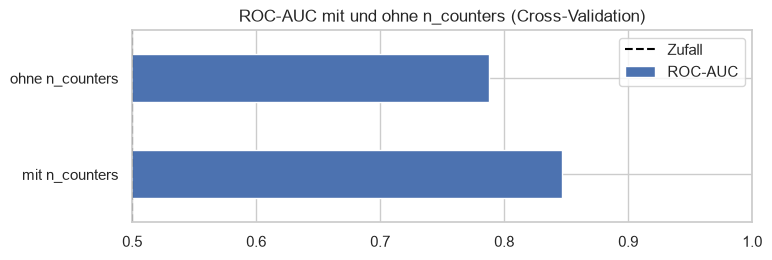

,ROC-AUC,ROC-AUC std,Recall,Precision
mit n_counters,0.847,0.005,0.664,0.202
ohne n_counters,0.788,0.004,0.543,0.162


In [ ]:
ohne_zaehler = pd.concat([
    evaluate_cv(clone(model), X_train, y_train, "mit n_counters"),
    evaluate_cv(clone(model), X_train.drop(columns=["n_counters"]), y_train, "ohne n_counters"),
])

ohne_zaehler["ROC-AUC"].plot(kind="barh", figsize=(8, 2.5))
plt.axvline(0.5, color="black", linestyle="--", label="Zufall")
plt.xlim(0.5, 1)
plt.title("ROC-AUC mit und ohne n_counters (Cross-Validation)")
plt.legend()
plt.show()

ohne_zaehler

**Was fällt auf?**
* Ohne `n_counters` fällt die ROC-AUC von **0,85 auf 0,79**. Etwa ein Drittel unseres Vorsprungs vor dem Zufall hängt an diesem einen Feature.
* Das Modell ist auch ohne `n_counters` noch deutlich besser als Zufall (0,5) und ungefähr so gut wie unsere Baseline (0,80).
* **Die Wahrheit liegt irgendwo zwischen 0,79 und 0,85.** Wo genau, kann nur STEG klären: mit dem Datum der Entdeckung und dem Grund für jeden Zählerwechsel.

**Entscheidung:** Wir behalten `n_counters` im Modell, nennen in der Präsentation aber beide Zahlen.

## 9 · Fazit
* Mit der Top-10-%-Schwelle findet das Modell knapp die Hälfte der Betrüger, und 28 % der Verdachtsfälle sind Betrug.
* Das Modell hängt **stark an der Anzahl der Zähler**. Das ist ein Risiko: Wenn ein Zähler erst **nach** dem Erwischen ausgetauscht wird, lernt das Modell zum Teil "schon erwischt" statt "betrügt" (siehe EDA 9.2). Ohne `n_counters` sinkt die ROC-AUC von 0,85 auf 0,79 (Abschnitt 8). Beide Zahlen gehören in die Präsentation.
* **Schwach** ist das Modell bei Kunden mit einem Zähler, neuen Kunden und Kunden mit wenigen Rechnungen.
* Ideen für später: Features, die nicht von der Zähleranzahl abhängen (z. B. Verbrauch im Vergleich zu ähnlichen Kunden in derselben Region), und von STEG das Datum der Entdeckung, um das Leakage sauber zu prüfen.